# Travelers' Inn: Early Booking Fall-Through Risk

**AIAP Batch 25 Technical Assessment - Exploratory Data Analysis**<br>
**Candidate:** Lim En Le<br>
**Application email:** georgelim330@gmail.com

This notebook refines the business request into one predictive question: **using information available when a booking is confirmed, which reservations are likely to end in cancellation or no-show rather than an honoured stay?**

The reader-facing goal is to explain the evidence, its business meaning, and how it shapes a leakage-safe modelling pipeline. It does not claim that prediction alone recovers revenue.

In [1]:
from pathlib import Path
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from src.data import clean_bookings, ensure_database, load_hotel_tables
from src.features import build_features

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 25
# Fetches the published database if it is not already present locally, so the
# notebook runs on a clean checkout exactly as the pipeline does.
DATA_PATH = ensure_database(Path("data/hotel.db"))
DEVELOPMENT_END_YEAR = 2024
FINAL_TEST_YEAR = 2025

BLUE = "#2F5D8A"
ORANGE = "#D68C45"
GOLD = "#C6A15B"
INK = "#28323C"
GREY = "#D9E0E6"
PALETTE = [BLUE, ORANGE, GOLD, "#7A8F6A", "#B46A86"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titleweight": "bold",
    "axes.labelcolor": INK,
    "axes.edgecolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "font.family": "DejaVu Sans",
})

In [2]:
raw_bookings, raw_reviews = load_hotel_tables(DATA_PATH)
bookings, cleaning_audit = clean_bookings(raw_bookings)
features = build_features(bookings)

total_nights = bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
bookings["total_nights"] = total_nights
bookings["total_guests"] = bookings["adults"] + bookings["children"] + bookings["babies"]
bookings["potential_booking_value"] = bookings["adr"] * total_nights

# Every chart below is drawn from `development` only. The 2025 block is separated
# here, once, and is never used to choose a feature, a model, or a threshold.
arrival_year = bookings["arrival_date"].dt.year
development = bookings.loc[arrival_year <= DEVELOPMENT_END_YEAR].copy()
test_holdout = bookings.loc[arrival_year == FINAL_TEST_YEAR].copy()

assert development["arrival_date"].dt.year.max() == DEVELOPMENT_END_YEAR
assert test_holdout["arrival_date"].dt.year.min() == FINAL_TEST_YEAR
assert set(development.index).isdisjoint(test_holdout.index)
assert len(development) + len(test_holdout) == len(bookings)

In [3]:
dev_rate = development["fall_through"].mean()
city_rate = development.loc[development["hotel"].eq("City Hotel"), "fall_through"].mean()
airport_rate = development.loc[development["hotel"].eq("Airport Hotel"), "fall_through"].mean()
display(Markdown(f'''
## tl;dr

- The SQLite source contains **{len(raw_bookings):,} booking rows** and **{len(raw_reviews):,} review rows**. Cleaning removes **{cleaning_audit['exact_duplicate_rows_removed']:,} exact duplicate bookings**, leaving **{len(bookings):,} unique reservations**.
- The leakage-safe development period contains **{len(development):,} bookings from 2023-2024**; **{dev_rate:.1%}** fell through. The 2025 block (**{len(test_holdout):,} bookings**) is reserved for final model evaluation and is not used in the feature-relationship charts below.
- Development-period fall-through is materially higher at City Hotel (**{city_rate:.1%}**) than Airport Hotel (**{airport_rate:.1%}**), and varies strongly with booking channel, deposit type, lead time, and customer history.
- Reviews occur only after honoured stays in this dataset. Rating, comment, and review-presence fields are useful as post-stay context but are **prohibited predictors**.
- The business output is a risk-ranked work queue using probability x potential booking value. It is **not** an estimate of causally recovered revenue.
'''))


## tl;dr

- The SQLite source contains **118,549 booking rows** and **17,583 review rows**. Cleaning removes **353 exact duplicate bookings**, leaving **118,196 unique reservations**.
- The leakage-safe development period contains **77,577 bookings from 2023-2024**; **35.2%** fell through. The 2025 block (**40,619 bookings**) is reserved for final model evaluation and is not used in the feature-relationship charts below.
- Development-period fall-through is materially higher at City Hotel (**39.8%**) than Airport Hotel (**26.0%**), and varies strongly with booking channel, deposit type, lead time, and customer history.
- Reviews occur only after honoured stays in this dataset. Rating, comment, and review-presence fields are useful as post-stay context but are **prohibited predictors**.
- The business output is a risk-ranked work queue using probability x potential booking value. It is **not** an estimate of causally recovered revenue.


## Context & Methods

### Decision and intended user

Revenue and reservation teams need an early warning signal at booking confirmation. The model will estimate `P(cancellation or no-show)` and optionally prioritize high-risk bookings by estimated booking value. A human team, not the model, decides whether to reconfirm, remind, review policy, or take no action.

### Key assumptions

1. Scoring occurs when a booking is confirmed; `days_in_waiting_list` is therefore known.
2. Final outcome fields and fields updated through cancellation/check-in are unavailable at scoring time.
3. Association is not causation. Segment differences do not prove that changing a deposit or channel will change outcomes.
4. The final 2025 period is held out from detailed EDA and model selection. Full-period access is used only for schema/data-quality validation.

### Visual design plan

| Figure | Analytical question | Form and scope | Honest-read controls |
|---|---|---|---|
| Target mix | How common is each outcome? | Zero-based bar, 2023-2024 | Counts and percentages labelled |
| Hotel comparison | Does risk differ by property? | Zero-based rate bar, 2023-2024 | Sample size on each bar |
| Lead time | How does advance notice relate to risk? | Ordered bins, 2023-2024 | Fixed, interpretable booking windows |
| Channel/deposit/history | Which booking-time groups differ? | Sorted/ordered bars, 2023-2024 | Rates shown with group sizes; no causal wording |
| Monthly pattern | Is there genuine temporal shape? | 17-month line, 2023-2024 | Common y-scale and property comparator |
| Booking value | How does risk vary across value? | Development-fitted deciles | Equal-frequency bins; test not used |
| Reviews | What post-stay context is available? | Rating distribution | Explicitly separated from predictors |

## Data

### 1. Database overview

**Purpose.** Confirm the physical source, table grain, schema, and keys before analysis. The expected grains are one row per reservation in `bookings` and one row per submitted review in `reviews`.

In [4]:
connection = sqlite3.connect(f"file:{Path(DATA_PATH).resolve().as_posix()}?mode=ro", uri=True)
try:
    table_names = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", connection
    )["name"].tolist()
    overview_rows = []
    schema_rows = []
    for table in table_names:
        row_count = connection.execute(f'SELECT COUNT(*) FROM "{table}"').fetchone()[0]
        columns = connection.execute(f'PRAGMA table_info("{table}")').fetchall()
        overview_rows.append({"table": table, "rows": row_count, "columns": len(columns)})
        schema_rows.extend(
            {"table": table, "column": col[1], "sqlite_type": col[2], "declared_primary_key": bool(col[5])}
            for col in columns
        )
finally:
    connection.close()

overview = pd.DataFrame(overview_rows)
schema = pd.DataFrame(schema_rows)
display(overview)
display(Markdown(
    f"Both tables store every field as SQLite `TEXT`, and no primary/foreign key is enforced. "
    f"Type inference and integrity checks must therefore happen explicitly in code."
))

,table,rows,columns
0,bookings,118549,36
1,reviews,17583,3


Both tables store every field as SQLite `TEXT`, and no primary/foreign key is enforced. Type inference and integrity checks must therefore happen explicitly in code.

### 2. Data-quality audit

**Question.** Which source issues could bias EDA, split bookings incorrectly, or break a production pipeline?

**Method.** Check exact duplicates and candidate keys, missing/sentinel values, numeric/date conformance, controlled categories, target consistency, impossible values, and robust outliers. Suspicious values are reported before any rule is applied.

In [5]:
def missing_count(series):
    text = series.astype("string").str.strip()
    return int(text.isna().sum() + text.str.casefold().isin({"", "null", "none", "nan"}).sum())

missing_rows = []
for table_name, frame in [("bookings", raw_bookings), ("reviews", raw_reviews)]:
    for column in frame.columns:
        count = missing_count(frame[column])
        if count:
            missing_rows.append({
                "table": table_name,
                "column": column,
                "missing_or_blank": count,
                "percent": 100 * count / len(frame),
            })
missing_table = pd.DataFrame(missing_rows).sort_values("percent", ascending=False)
display(missing_table.style.format({"percent": "{:.2f}%"}))

,table,column,missing_or_blank,percent
6,bookings,company,83513,70.45%
8,bookings,promo_code,48491,40.90%
5,bookings,agent,16281,13.73%
9,reviews,comments,341,1.94%
2,bookings,country,825,0.70%
7,bookings,customer_type,386,0.33%
1,bookings,meal,363,0.31%
0,bookings,arrival_date_week_number,362,0.31%
4,bookings,distribution_channel,346,0.29%
3,bookings,market_segment,327,0.28%


In [6]:
raw_week = pd.to_numeric(raw_bookings["arrival_date_week_number"].astype("string").str.strip(), errors="coerce")
valid_week = raw_week.notna()
derived_week = pd.Series(
    pd.to_datetime(pd.DataFrame({
        "year": pd.to_numeric(raw_bookings["arrival_date_year"]),
        "month": raw_bookings["arrival_date_month"].str.strip().str.lower().str[:3].map(
            {m[:3].lower(): i for i, m in enumerate(
                ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"], 1
            )}
        ),
        "day": pd.to_numeric(raw_bookings["arrival_date_day_of_month"]),
    })).dt.isocalendar().week.astype(float)
)
raw_rating = pd.to_numeric(raw_reviews["rating"], errors="coerce")
clean_nights = bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
clean_guests = bookings["adults"] + bookings["children"] + bookings["babies"]

quality_findings = pd.DataFrame([
    ["Exact duplicate booking rows", cleaning_audit["exact_duplicate_rows_removed"], "Drop only byte-equivalent duplicates; conflicting duplicate IDs fail closed."],
    ["Exact duplicate review rows beyond first", int(raw_reviews.duplicated().sum()), "Keep reviews context-only; deduplicate before any review summary."],
    ["Malformed lead_time values", cleaning_audit["numeric_malformed_to_missing"]["lead_time"], "Coerce to missing; median imputation is fitted on training data."],
    ["Negative lead_time values", cleaning_audit["negative_values_invalidated"]["lead_time"], "Impossible at confirmation; set to missing and retain a missingness indicator."],
    ["Malformed adr values", cleaning_audit["numeric_malformed_to_missing"]["adr"], "Coerce to missing; do not invent a room rate."],
    ["Arrival week missing/malformed", int((~valid_week).sum()), "Drop supplied week number from modelling."],
    ["Arrival week inconsistent with date", int((valid_week & raw_week.ne(derived_week)).sum()), "Derive cyclic month/weekday from validated date instead."],
    ["Zero-night bookings", int(clean_nights.eq(0).sum()), "Retain and flag; day-use versus data error is unresolved."],
    ["Zero-guest bookings", int(clean_guests.eq(0).sum()), "Retain and flag; do not silently delete."],
    ["Ratings outside documented 1-5", int((raw_rating.notna() & ~raw_rating.between(1, 5)).sum()), "Exclude reviews from predictors; report as context-quality issue."],
], columns=["observed_issue", "rows_affected", "rule_and_justification"])
display(quality_findings)

,observed_issue,rows_affected,rule_and_justification
0,Exact duplicate booking rows,353,Drop only byte-equivalent duplicates; conflict...
1,Exact duplicate review rows beyond first,51,Keep reviews context-only; deduplicate before ...
2,Malformed lead_time values,50,Coerce to missing; median imputation is fitted...
3,Negative lead_time values,300,Impossible at confirmation; set to missing and...
4,Malformed adr values,318,Coerce to missing; do not invent a room rate.
5,Arrival week missing/malformed,490,Drop supplied week number from modelling.
6,Arrival week inconsistent with date,63722,Derive cyclic month/weekday from validated dat...
7,Zero-night bookings,625,Retain and flag; day-use versus data error is ...
8,Zero-guest bookings,187,Retain and flag; do not silently delete.
9,Ratings outside documented 1-5,174,Exclude reviews from predictors; report as con...


In [7]:
category_changes = pd.Series(cleaning_audit["category_values_canonicalized"], name="rows_canonicalized")
numeric_malformed = pd.Series(cleaning_audit["numeric_malformed_to_missing"], name="malformed_to_missing")
display(pd.concat([category_changes, numeric_malformed], axis=1).fillna(0).astype(int))
malformed_adr_tokens = (
    raw_bookings.loc[pd.to_numeric(raw_bookings["adr"], errors="coerce").isna(), "adr"]
    .astype("string").str.strip().value_counts().head(6)
)
display(Markdown("**Sample of the malformed `adr` tokens (count in the raw table):**"))
display(malformed_adr_tokens.to_frame("rows"))
display(Markdown(
    "**Interpretation.** The problems are format inconsistency rather than missing outcomes: the "
    "malformed values carry a European decimal comma (`276,00`), a currency prefix (`SGD 253.00`), or "
    "a unit suffix on lead time (`14 days`). A parsing rule would recover all 318 `adr` and all 50 "
    "`lead_time` values.\n\n"
    "**They are nonetheless coerced to missing in this pipeline, and that is a deliberate, "
    "acknowledged cost.** By the time the recoverability was quantified, the 2025 block had already been "
    "scored, and changing a model input would have required re-running model and threshold selection and "
    "re-reporting the final metrics — spending the holdout to gain roughly 0.3% of rows. The affected "
    "bookings are median-imputed and, because their ADR is missing, contribute zero potential booking "
    "value (117 rows worth about S$118,000 in the test block). Recovering them is the first item in the "
    "data-quality backlog, to be done together with a fresh evaluation period.\n\n"
    "Rules are otherwise deterministic, counts are retained in the cleaning audit, and model-fitted "
    "imputation occurs only after the temporal split. The supplied arrival week is not trustworthy "
    "enough to retain: it is missing or malformed on 490 rows and disagrees with the validated arrival "
    "date on 63,722 more."
))

,rows_canonicalized,malformed_to_missing
hotel,0,0
meal,228,0
country,5780,0
market_segment,868,0
distribution_channel,296,0
reserved_room_type,0,0
deposit_type,1074,0
customer_type,631,0
promo_code,0,0
lead_time,0,50


**Sample of the malformed `adr` tokens (count in the raw table):**

,rows
adr,
"0,00",6
"276,00",5
"149,50",5
"172,50",4
SGD 253.00,4
SGD 172.50,4


**Interpretation.** The problems are format inconsistency rather than missing outcomes: the malformed values carry a European decimal comma (`276,00`), a currency prefix (`SGD 253.00`), or a unit suffix on lead time (`14 days`). A parsing rule would recover all 318 `adr` and all 50 `lead_time` values.

**They are nonetheless coerced to missing in this pipeline, and that is a deliberate, acknowledged cost.** By the time the recoverability was quantified, the 2025 block had already been scored, and changing a model input would have required re-running model and threshold selection and re-reporting the final metrics — spending the holdout to gain roughly 0.3% of rows. The affected bookings are median-imputed and, because their ADR is missing, contribute zero potential booking value (117 rows worth about S$118,000 in the test block). Recovering them is the first item in the data-quality backlog, to be done together with a fresh evaluation period.

Rules are otherwise deterministic, counts are retained in the cleaning audit, and model-fitted imputation occurs only after the temporal split. The supplied arrival week is not trustworthy enough to retain: it is missing or malformed on 490 rows and disagrees with the validated arrival date on 63,722 more.

### 3. Target construction and validation

**Question.** Does the documented cancellation flag agree with the final reservation status, including no-shows?

**Rule.** `fall_through = 1` for `Canceled` or `No-Show`; `fall_through = 0` for `Check-Out`. The status is used only to construct the label and is then removed from the feature matrix.

In [8]:
target_crosscheck = pd.crosstab(
    bookings["is_canceled_normalized"], bookings["reservation_status"],
    rownames=["normalized is_canceled"], colnames=["final status"], margins=True,
)
display(target_crosscheck)
display(Markdown(
    f"All **{len(bookings):,} deduplicated bookings** are consistent after mapping the observed boolean spellings. "
    f"The label contains **{int(bookings['fall_through'].sum()):,} fall-throughs ({bookings['fall_through'].mean():.1%})** across all years. "
    "No predictor receives `is_canceled`, final status, or status date."
))

final status,Canceled,Check-Out,No-Show,All
normalized is_canceled,,,,
0,0,75168,0,75168
1,41849,0,1179,43028
All,41849,75168,1179,118196


All **118,196 deduplicated bookings** are consistent after mapping the observed boolean spellings. The label contains **43,028 fall-throughs (36.4%)** across all years. No predictor receives `is_canceled`, final status, or status date.

## Results

### 4. Development-period target distribution

**Question.** How imbalanced is the prediction target before model selection?

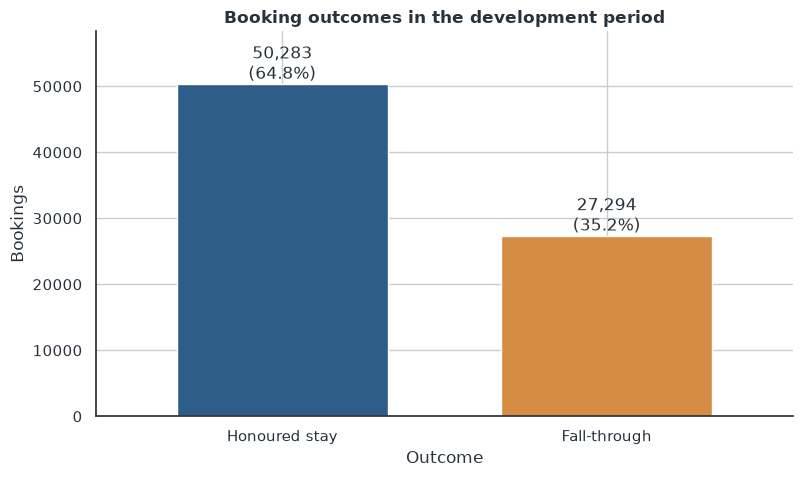

**Meaning.** Fall-throughs are common (**35.2%**) rather than a rare-event edge case. Accuracy alone would still reward majority-class predictions, so ROC-AUC, average precision, recall/precision/F1, Brier score, and calibration are required.

In [9]:
target_counts = development["fall_through"].map({0: "Honoured stay", 1: "Fall-through"}).value_counts()
ax = target_counts.reindex(["Honoured stay", "Fall-through"]).plot.bar(color=[BLUE, ORANGE], width=0.65)
ax.set(title="Booking outcomes in the development period", xlabel="Outcome", ylabel="Bookings")
ax.tick_params(axis="x", rotation=0)
for patch, count in zip(ax.patches, target_counts.reindex(["Honoured stay", "Fall-through"])):
    ax.text(patch.get_x() + patch.get_width()/2, patch.get_height(), f"{count:,}\n({count/len(development):.1%})", ha="center", va="bottom")
ax.set_ylim(0, target_counts.max() * 1.16)
sns.despine()
plt.show()
display(Markdown(
    f"**Meaning.** Fall-throughs are common (**{development['fall_through'].mean():.1%}**) rather than a rare-event edge case. "
    "Accuracy alone would still reward majority-class predictions, so ROC-AUC, average precision, recall/precision/F1, Brier score, and calibration are required."
))

### 5. Property comparison

**Question.** Is fall-through risk similar enough to pool both hotels without a property feature?

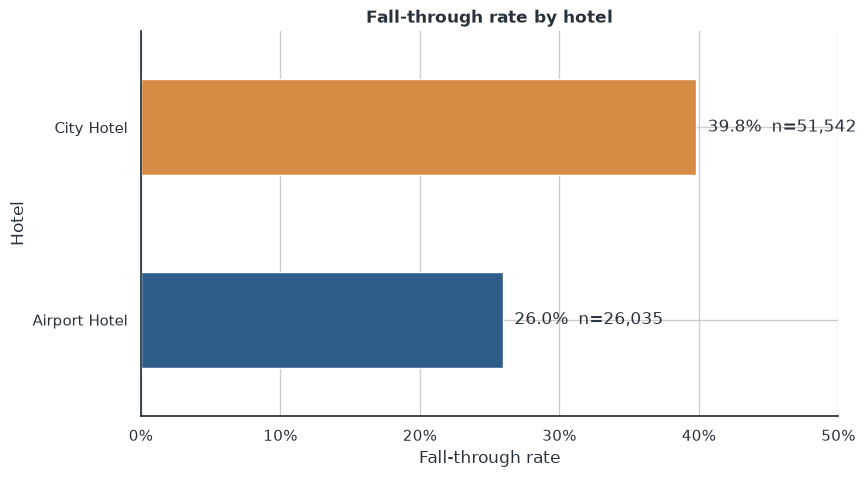

**Meaning.** The property gap is **13.9%** in the development period. Hotel identity is known at booking and should be retained. The chart is descriptive; it does not establish that property operations cause the difference.

In [10]:
hotel_rates = development.groupby("hotel")["fall_through"].agg(["mean", "count"]).sort_values("mean")
ax = hotel_rates["mean"].plot.barh(color=[BLUE, ORANGE])
ax.set(title="Fall-through rate by hotel", xlabel="Fall-through rate", ylabel="Hotel", xlim=(0, max(0.5, hotel_rates['mean'].max()*1.2)))
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for patch, (_, row) in zip(ax.patches, hotel_rates.iterrows()):
    ax.text(patch.get_width() + 0.008, patch.get_y()+patch.get_height()/2, f"{row['mean']:.1%}  n={int(row['count']):,}", va="center")
sns.despine()
plt.show()
gap = hotel_rates["mean"].max() - hotel_rates["mean"].min()
display(Markdown(
    f"**Meaning.** The property gap is **{gap:.1%}** in the development period. Hotel identity is known at booking and should be retained. "
    "The chart is descriptive; it does not establish that property operations cause the difference."
))

### 6. Lead time

**Question.** Does booking further in advance identify a materially different risk profile?

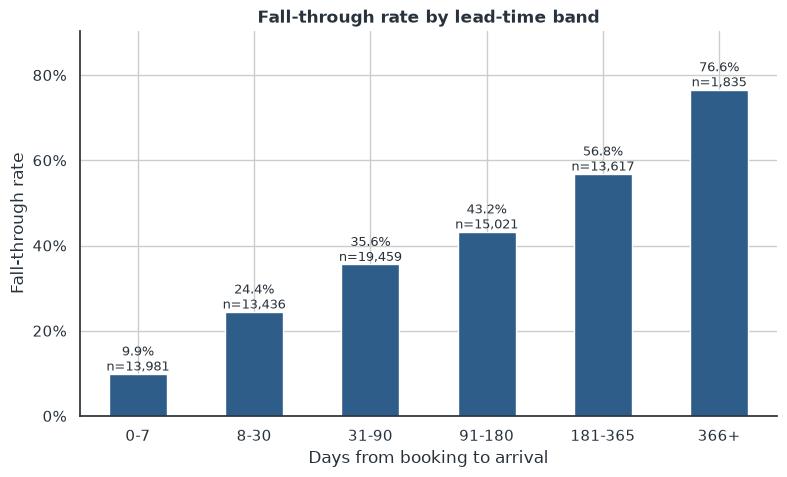

**Meaning.** Risk rises from **9.9%** for 0-7 days to **76.6%** for 366+ days. Retain lead time, treat its observed negative values as missing, and use robust scaling for the linear model.

In [11]:
lead_bins = [-0.001, 7, 30, 90, 180, 365, np.inf]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
lead_frame = development.dropna(subset=["lead_time"]).copy()
lead_frame["lead_time_band"] = pd.cut(lead_frame["lead_time"], bins=lead_bins, labels=lead_labels)
lead_rates = lead_frame.groupby("lead_time_band", observed=True)["fall_through"].agg(["mean", "count"])
ax = lead_rates["mean"].plot.bar(color=BLUE)
ax.set(title="Fall-through rate by lead-time band", xlabel="Days from booking to arrival", ylabel="Fall-through rate", ylim=(0, lead_rates['mean'].max()*1.18))
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.tick_params(axis="x", rotation=0)
for patch, (_, row) in zip(ax.patches, lead_rates.iterrows()):
    ax.text(patch.get_x()+patch.get_width()/2, patch.get_height()+0.008, f"{row['mean']:.1%}\nn={int(row['count']):,}", ha="center", fontsize=9)
sns.despine()
plt.show()
display(Markdown(
    f"**Meaning.** Risk rises from **{lead_rates.iloc[0]['mean']:.1%}** for 0-7 days to **{lead_rates.iloc[-1]['mean']:.1%}** for 366+ days. "
    "Retain lead time, treat its observed negative values as missing, and use robust scaling for the linear model."
))

### 7. Market segment and distribution channel

**Question.** Which booking channels differ enough to support targeted, channel-aware risk estimation?

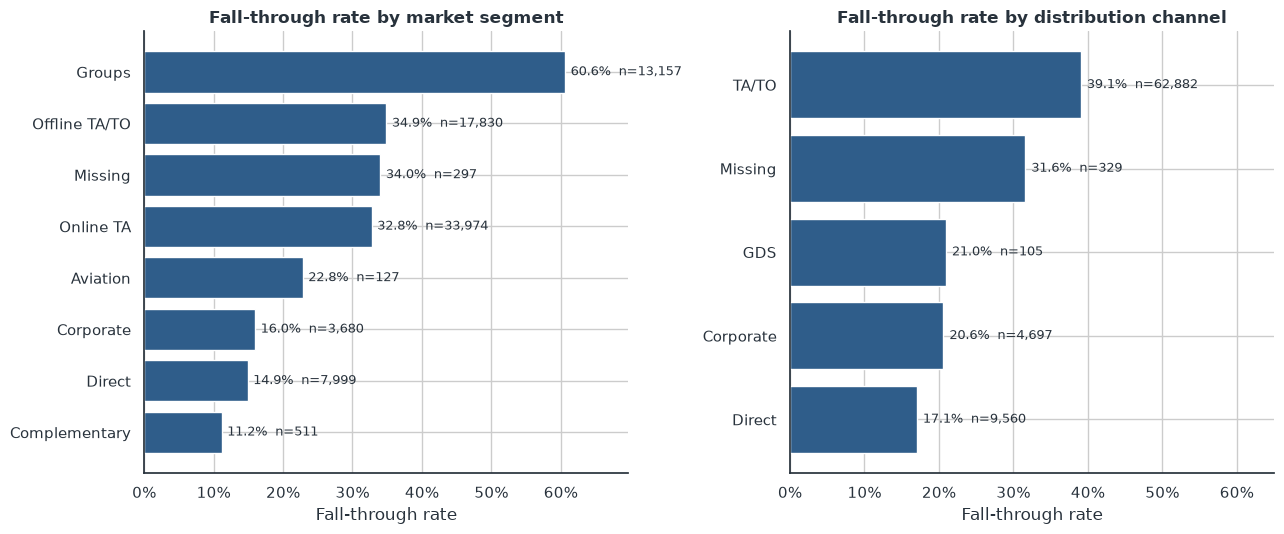

**Meaning.** Group bookings fall through at **60.6%**, compared with **14.9%** for Direct bookings. Canonicalization prevents spelling variants from fragmenting these groups. Segment and channel are booking-time predictors; intervention policy should still account for differing customer relationships and costs.

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for axis, column, title in [
    (axes[0], "market_segment", "Market segment"),
    (axes[1], "distribution_channel", "Distribution channel"),
]:
    summary = development.groupby(column)["fall_through"].agg(["mean", "count"])
    summary = summary.loc[summary["count"] >= 100].sort_values("mean")
    axis.barh(summary.index, summary["mean"], color=BLUE)
    axis.set(title=f"Fall-through rate by {title.lower()}", xlabel="Fall-through rate", ylabel="")
    axis.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    axis.set_xlim(0, max(0.65, summary["mean"].max()*1.15))
    for y, (_, row) in enumerate(summary.iterrows()):
        axis.text(row["mean"]+0.008, y, f"{row['mean']:.1%}  n={int(row['count']):,}", va="center", fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()
group_rate = development.loc[development["market_segment"].eq("Groups"), "fall_through"].mean()
direct_rate = development.loc[development["market_segment"].eq("Direct"), "fall_through"].mean()
display(Markdown(
    f"**Meaning.** Group bookings fall through at **{group_rate:.1%}**, compared with **{direct_rate:.1%}** for Direct bookings. "
    "Canonicalization prevents spelling variants from fragmenting these groups. Segment and channel are booking-time predictors; intervention policy should still account for differing customer relationships and costs."
))

### 8. Deposit arrangement

**Question.** Is deposit type associated with outcome strongly enough to require special leakage and policy scrutiny?

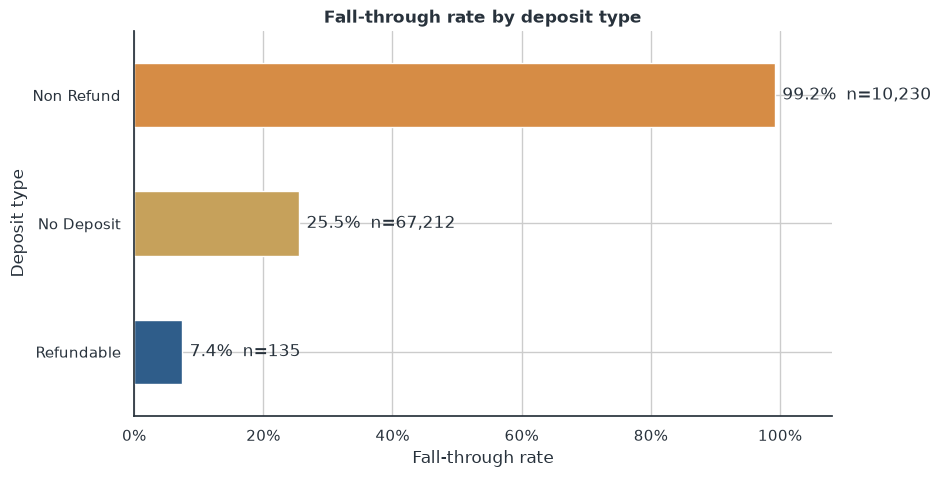

**Meaning.** Non-refundable bookings have a **99.2%** observed fall-through rate (n=10,230). This counter-intuitive association may reflect channel, group, or policy selection effects. Keep the booking-time feature, test temporal stability, and do not infer that making a booking non-refundable causes cancellation.

In [13]:
deposit_rates = development.groupby("deposit_type")["fall_through"].agg(["mean", "count"]).sort_values("mean")
ax = deposit_rates["mean"].plot.barh(color=[BLUE, GOLD, ORANGE][:len(deposit_rates)])
ax.set(title="Fall-through rate by deposit type", xlabel="Fall-through rate", ylabel="Deposit type", xlim=(0, 1.08))
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for patch, (_, row) in zip(ax.patches, deposit_rates.iterrows()):
    ax.text(patch.get_width()+0.012, patch.get_y()+patch.get_height()/2, f"{row['mean']:.1%}  n={int(row['count']):,}", va="center")
sns.despine()
plt.show()
non_refund = deposit_rates.loc["Non Refund"]
display(Markdown(
    f"**Meaning.** Non-refundable bookings have a **{non_refund['mean']:.1%}** observed fall-through rate (n={int(non_refund['count']):,}). "
    "This counter-intuitive association may reflect channel, group, or policy selection effects. Keep the booking-time feature, test temporal stability, and do not infer that making a booking non-refundable causes cancellation."
))

### 9. Customer booking history

**Question.** Do pre-existing customer-history signals separate risk in an operationally understandable way?

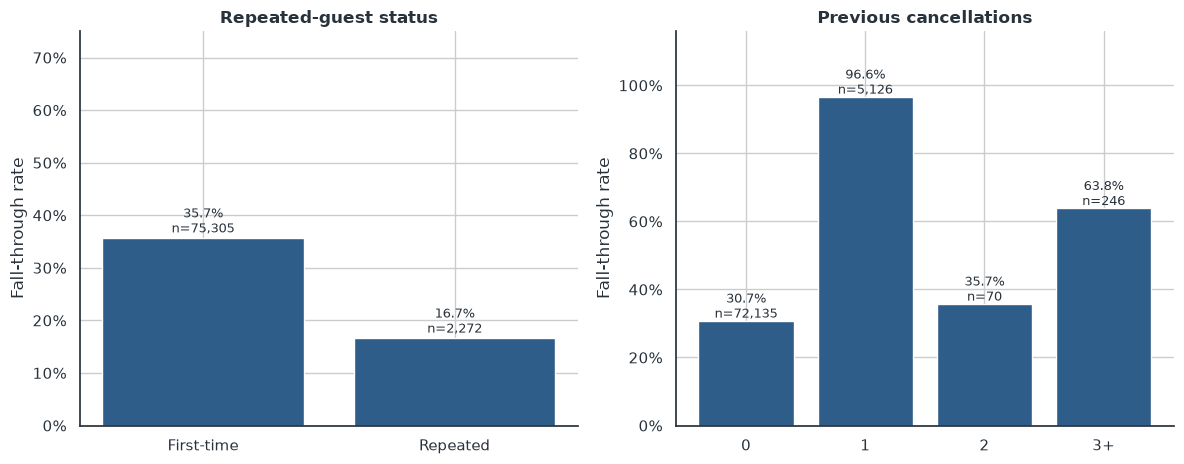

**Meaning.** History available before the current outcome is useful and explainable. Retain repeated-guest, prior-cancellation, and prior-honoured-booking counts. Rare high-count values should be handled by a tree model or robust scaling rather than deleted.

In [14]:
history = development.copy()
history["repeated_guest_label"] = history["is_repeated_guest"].map({0: "First-time", 1: "Repeated"})
history["prior_cancel_band"] = pd.cut(
    history["previous_cancellations"], bins=[-0.1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, column, title in [
    (axes[0], "repeated_guest_label", "Repeated-guest status"),
    (axes[1], "prior_cancel_band", "Previous cancellations"),
]:
    summary = history.groupby(column, observed=True)["fall_through"].agg(["mean", "count"])
    axis.bar(summary.index.astype(str), summary["mean"], color=BLUE)
    axis.set(title=title, xlabel="", ylabel="Fall-through rate", ylim=(0, max(0.75, summary['mean'].max()*1.2)))
    axis.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    for patch, (_, row) in zip(axis.patches, summary.iterrows()):
        axis.text(patch.get_x()+patch.get_width()/2, patch.get_height()+0.01, f"{row['mean']:.1%}\nn={int(row['count']):,}", ha="center", fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()
display(Markdown(
    "**Meaning.** History available before the current outcome is useful and explainable. Retain repeated-guest, prior-cancellation, and prior-honoured-booking counts. "
    "Rare high-count values should be handled by a tree model or robust scaling rather than deleted."
))

### 10. Stay characteristics and requests

**Question.** Do duration, special requests, and parking needs carry practical booking-time signal?

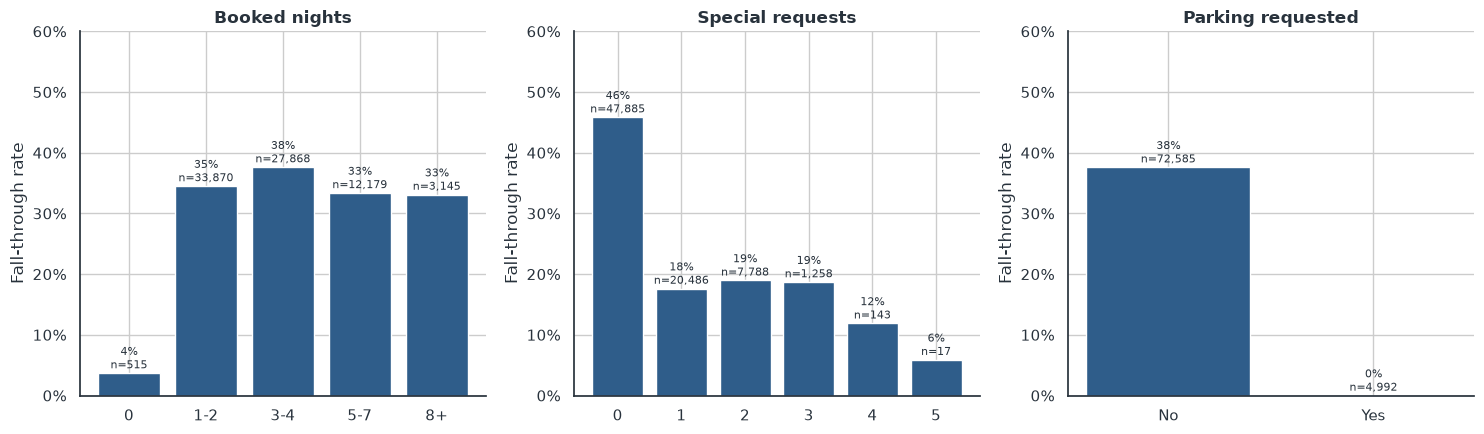

**Meaning.** Duration and request fields show monotonic or segment-level differences without requiring complex transformations. Engineer total nights, total guests, weekend share, zero-night/zero-guest flags, and potential booking value; retain the original booking-time counts.

In [15]:
stay = development.copy()
stay["night_band"] = pd.cut(stay["total_nights"], [-0.1, 0, 2, 4, 7, np.inf], labels=["0", "1-2", "3-4", "5-7", "8+"])
stay["parking_requested"] = np.where(stay["required_car_parking_spaces"].gt(0), "Yes", "No")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, column, title in [
    (axes[0], "night_band", "Booked nights"),
    (axes[1], "total_of_special_requests", "Special requests"),
    (axes[2], "parking_requested", "Parking requested"),
]:
    summary = stay.groupby(column, observed=True)["fall_through"].agg(["mean", "count"])
    axis.bar(summary.index.astype(str), summary["mean"], color=BLUE)
    axis.set(title=title, xlabel="", ylabel="Fall-through rate", ylim=(0, max(0.6, summary['mean'].max()*1.2)))
    axis.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    axis.tick_params(axis="x", rotation=0)
    for patch, (_, row) in zip(axis.patches, summary.iterrows()):
        axis.text(patch.get_x()+patch.get_width()/2, patch.get_height()+0.008, f"{row['mean']:.0%}\nn={int(row['count']):,}", ha="center", fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()
display(Markdown(
    "**Meaning.** Duration and request fields show monotonic or segment-level differences without requiring complex transformations. "
    "Engineer total nights, total guests, weekend share, zero-night/zero-guest flags, and potential booking value; retain the original booking-time counts."
))

### 11. Temporal patterns

**Question.** Does development-period risk vary over enough time points to justify seasonal features and temporal validation?

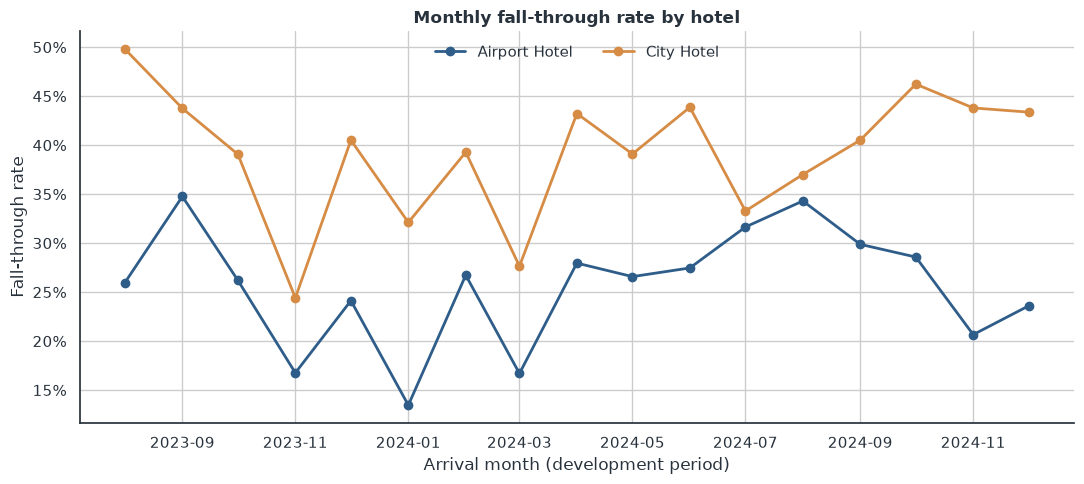

,role,first_month,last_month,months_present,bookings
year,,,,,
2023,train,8,12,5,"19,193"
2024,validation,1,12,12,"58,384"
2025,final test,1,8,8,"40,619"


**Meaning.** The development period supplies **17 monthly observations**, enough to show temporal variation rather than a two-point comparison. Use cyclic month/weekday features and a chronological train-validation-test design. Do not randomly mix future arrivals into training.

**A limitation this table makes explicit.** The calendar blocks are not comparable. The 2023 training block runs from August to December only, and the 2025 test block runs from January to August only, so **the model is trained without ever seeing a January-July arrival and is then tested almost entirely on them.** The cyclic month features must extrapolate across that gap, and season cannot be separated from year effects with this data. The chronological split is still the right choice — a random split would leak future booking patterns into training — but its blocks should not be read as like-for-like, and the year-on-year rate differences below partly reflect which months each block happens to contain.

In [16]:
monthly = (
    development.assign(arrival_month=development["arrival_date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["arrival_month", "hotel"])["fall_through"].agg(["mean", "count"]).reset_index()
)
fig, ax = plt.subplots(figsize=(11, 5))
for color, (hotel, group) in zip([BLUE, ORANGE], monthly.groupby("hotel")):
    ax.plot(group["arrival_month"], group["mean"], marker="o", linewidth=2, color=color, label=hotel)
ax.set(title="Monthly fall-through rate by hotel", xlabel="Arrival month (development period)", ylabel="Fall-through rate")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(frameon=False, ncol=2, loc="upper center")
sns.despine()
plt.tight_layout()
plt.show()
coverage = (
    bookings.assign(year=bookings["arrival_date"].dt.year, month=bookings["arrival_date"].dt.month)
    .groupby("year")
    .agg(
        role=("year", lambda s: {2023: "train", 2024: "validation", 2025: "final test"}[s.iloc[0]]),
        first_month=("month", "min"),
        last_month=("month", "max"),
        months_present=("month", "nunique"),
        bookings=("month", "size"),
    )
)
# Row counts and month coverage are schema facts. No 2025 outcome statistic is shown
# here; the holdout's fall-through rate belongs to the final evaluation, not the EDA.
display(coverage.style.format({"bookings": "{:,.0f}"}))
display(Markdown(
    f"**Meaning.** The development period supplies **{monthly['arrival_month'].nunique()} monthly observations**, enough to show temporal variation rather than a two-point comparison. "
    "Use cyclic month/weekday features and a chronological train-validation-test design. Do not randomly mix future arrivals into training.\n\n"
    "**A limitation this table makes explicit.** The calendar blocks are not comparable. The 2023 training "
    "block runs from August to December only, and the 2025 test block runs from January to August only, so "
    "**the model is trained without ever seeing a January-July arrival and is then tested almost entirely on "
    "them.** The cyclic month features must extrapolate across that gap, and season cannot be separated from "
    "year effects with this data. The chronological split is still the right choice — a random split would "
    "leak future booking patterns into training — but its blocks should not be read as like-for-like, and "
    "the year-on-year rate differences below partly reflect which months each block happens to contain."
))

### 12. ADR and booking-value prioritisation

**Question.** Is booking value useful for prioritising predicted risk, without turning the task into an ADR regression problem?

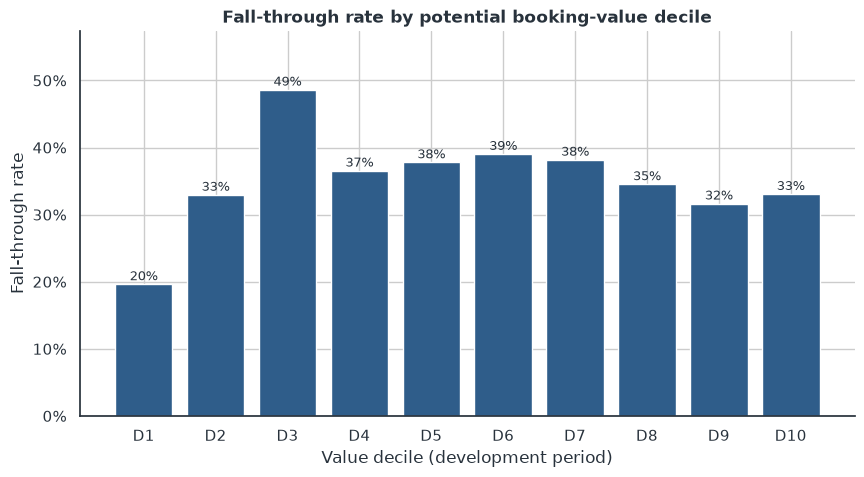

,fall_through_rate,median_value,bookings
value_decile,,,
D1,19.6%,S$117,"7,738"
D2,33.0%,S$230,"7,738"
D3,48.6%,S$304,"7,737"
D4,36.6%,S$421,"7,738"
D5,37.8%,S$524,"7,737"
D6,39.0%,S$624,"7,738"
D7,38.2%,S$759,"7,737"
D8,34.5%,S$952,"7,738"
D9,31.7%,"S$1,304","7,737"


**Meaning.** ADR and booked nights are known at confirmation and can create `potential_booking_value = ADR x total nights`. Multiplying that value by predicted risk gives a prioritisation score, not a promise of recovery. Classification remains the primary task because the operational problem is fall-through, not price optimization.

In [17]:
value_frame = development.dropna(subset=["potential_booking_value"]).copy()
value_frame = value_frame.loc[value_frame["potential_booking_value"].ge(0)]
value_frame["value_decile"] = pd.qcut(
    value_frame["potential_booking_value"].rank(method="first"), 10,
    labels=[f"D{i}" for i in range(1, 11)]
)
value_summary = value_frame.groupby("value_decile", observed=True).agg(
    fall_through_rate=("fall_through", "mean"),
    median_value=("potential_booking_value", "median"),
    bookings=("fall_through", "size"),
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(value_summary.index.astype(str), value_summary["fall_through_rate"], color=BLUE)
ax.set(title="Fall-through rate by potential booking-value decile", xlabel="Value decile (development period)", ylabel="Fall-through rate", ylim=(0, value_summary['fall_through_rate'].max()*1.18))
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
for patch, (_, row) in zip(ax.patches, value_summary.iterrows()):
    ax.text(patch.get_x()+patch.get_width()/2, patch.get_height()+0.006, f"{row['fall_through_rate']:.0%}", ha="center", fontsize=9)
sns.despine()
plt.show()
display(value_summary.style.format({"fall_through_rate": "{:.1%}", "median_value": "S${:,.0f}", "bookings": "{:,.0f}"}))
display(Markdown(
    "**Meaning.** ADR and booked nights are known at confirmation and can create `potential_booking_value = ADR x total nights`. "
    "Multiplying that value by predicted risk gives a prioritisation score, not a promise of recovery. Classification remains the primary task because the operational problem is fall-through, not price optimization."
))

### 13. Reviews as post-stay context only

**Question.** What can reviews tell management, and why must they stay out of the predictive feature set?

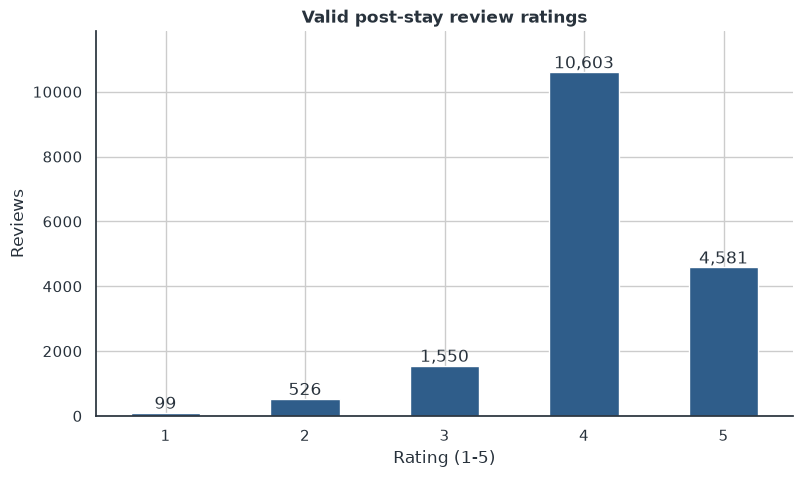

reservation_status,Canceled,Check-Out,No-Show
client_email,,,
False,41849,57636,1179
True,0,17532,0


After removing exact duplicates, **17,532 reviews** remain; **173** ratings are outside the documented range. Every linked reviewed booking is a Check-Out. Review presence therefore reveals the outcome, while rating/comments occur after the stay. Use reviews only for a separate customer-experience analysis, never for this early-risk model.

In [18]:
dedup_reviews = raw_reviews.drop_duplicates().copy()
dedup_reviews["rating_numeric"] = pd.to_numeric(dedup_reviews["rating"], errors="coerce")
valid_reviews = dedup_reviews.loc[dedup_reviews["rating_numeric"].between(1, 5)]
rating_counts = valid_reviews["rating_numeric"].value_counts().sort_index()
ax = rating_counts.plot.bar(color=BLUE)
ax.set(title="Valid post-stay review ratings", xlabel="Rating (1-5)", ylabel="Reviews")
ax.tick_params(axis="x", rotation=0)
for patch, count in zip(ax.patches, rating_counts):
    ax.text(patch.get_x()+patch.get_width()/2, patch.get_height(), f"{count:,}", ha="center", va="bottom")
ax.set_ylim(0, rating_counts.max()*1.12)
sns.despine()
plt.show()

review_emails = set(dedup_reviews["client_email"].astype("string"))
review_link = bookings["client_email"].astype("string").isin(review_emails)
review_outcomes = pd.crosstab(review_link, bookings["reservation_status"])
display(review_outcomes)
display(Markdown(
    f"After removing exact duplicates, **{len(dedup_reviews):,} reviews** remain; **{int((~dedup_reviews['rating_numeric'].between(1,5)).sum()):,}** ratings are outside the documented range. "
    "Every linked reviewed booking is a Check-Out. Review presence therefore reveals the outcome, while rating/comments occur after the stay. "
    "Use reviews only for a separate customer-experience analysis, never for this early-risk model."
))

### 14. Explicit leakage audit

The table fixes the scoring-time contract. When timing is uncertain, the conservative decision is to drop the feature.

In [19]:
leakage_audit = pd.DataFrame([
    ["Unnamed: 0", "Drop", "Export index; no business meaning", "Dataset creation", "High"],
    ["booking_id", "Drop", "Identifier; memorisation risk", "Booking", "High"],
    ["client_email", "Drop", "Direct identifier and privacy risk", "Booking", "High"],
    ["is_canceled", "Target only", "Direct outcome label", "Final outcome", "Certain"],
    ["reservation_status", "Target only", "Constructs cancellation/no-show label", "Final outcome", "Certain"],
    ["reservation_status_date", "Drop", "Date final status was set", "Final outcome", "Certain"],
    ["assigned_room_type", "Drop", "Actually assigned at check-in", "Check-in", "High"],
    ["booking_changes", "Drop", "Accumulates changes until check-in/cancellation", "Through outcome", "High"],
    ["rating / comments", "Drop", "Post-stay feedback", "After stay", "Certain"],
    ["review presence", "Drop", "Perfectly identifies honoured stays here", "After stay", "Certain"],
    ["agent / company IDs", "Transform", "Known, but unstable high-cardinality identity", "Booking", "Medium"],
    ["days_in_waiting_list", "Keep", "Known when booking is confirmed", "Confirmation", "Low"],
    ["deposit_type / promo_code", "Keep", "Terms known at confirmation", "Confirmation", "Low"],
    ["reserved_room_type / ADR / nights", "Keep", "Booking terms available for scoring", "Confirmation", "Low"],
    ["prior booking history", "Keep", "Explicitly prior to current booking", "Booking", "Low"],
], columns=["feature", "keep_or_drop", "reason", "availability_time", "leakage_risk"])
display(leakage_audit)
display(Markdown(
    f"The resulting model matrix has **{features.shape[1]} features** after deterministic engineering and contains none of the prohibited columns. "
    "Agent/company are represented only by presence indicators; raw IDs are excluded."
))

,feature,keep_or_drop,reason,availability_time,leakage_risk
0,Unnamed: 0,Drop,Export index; no business meaning,Dataset creation,High
1,booking_id,Drop,Identifier; memorisation risk,Booking,High
2,client_email,Drop,Direct identifier and privacy risk,Booking,High
3,is_canceled,Target only,Direct outcome label,Final outcome,Certain
4,reservation_status,Target only,Constructs cancellation/no-show label,Final outcome,Certain
5,reservation_status_date,Drop,Date final status was set,Final outcome,Certain
6,assigned_room_type,Drop,Actually assigned at check-in,Check-in,High
7,booking_changes,Drop,Accumulates changes until check-in/cancellation,Through outcome,High
8,rating / comments,Drop,Post-stay feedback,After stay,Certain
9,review presence,Drop,Perfectly identifies honoured stays here,After stay,Certain


The resulting model matrix has **37 features** after deterministic engineering and contains none of the prohibited columns. Agent/company are represented only by presence indicators; raw IDs are excluded.

## Takeaways

### 15. Key findings and modelling implications

In [20]:
display(Markdown(f'''
1. **Problem selected:** predict fall-through (cancellation or no-show) at booking confirmation; classify first, then prioritize by expected revenue at risk.
2. **Target quality:** final status and normalized `is_canceled` agree on all **{len(bookings):,} deduplicated rows**. Status fields are label-only.
3. **Data handling:** remove **{cleaning_audit['exact_duplicate_rows_removed']:,} exact duplicate bookings**; coerce malformed/negative numeric values to missing with counts; canonicalize observed categories; retain ambiguous zero-night/zero-guest rows with flags.
4. **Feature engineering:** total nights, total guests, weekend share, cyclic arrival month/weekday, potential booking value, missingness/presence indicators, and zero-night/zero-guest flags. All are available by confirmation.
5. **Evaluation design:** train on 2023, select model/hyperparameters/threshold on 2024, and evaluate the frozen decision on 2025. Transformations are fitted inside sklearn pipelines.
6. **Model set:** DummyClassifier for prevalence, Logistic Regression for an interpretable linear benchmark, and HistGradientBoosting for nonlinearities/interactions without an extra compiled dependency.
7. **Business use:** a probability-ranked reconfirmation/work queue. Prediction, intervention, and causal revenue recovery are separate questions; uplift requires controlled experiments.

### Limitations visible in the EDA

- The calendar spans partial years (2023 starts in August; 2025 ends in August), so year-on-year seasonality is not perfectly balanced.
- Deposit and channel associations may reflect selection effects and policy, not causal levers.
- Several fields are documented only at a broad level; production scoring needs a feature-availability contract with source-system owners.
- No intervention-cost, room-capacity, or causal-outcome data is present, so an optimal profit threshold cannot be estimated from this dataset alone.
'''))


1. **Problem selected:** predict fall-through (cancellation or no-show) at booking confirmation; classify first, then prioritize by expected revenue at risk.
2. **Target quality:** final status and normalized `is_canceled` agree on all **118,196 deduplicated rows**. Status fields are label-only.
3. **Data handling:** remove **353 exact duplicate bookings**; coerce malformed/negative numeric values to missing with counts; canonicalize observed categories; retain ambiguous zero-night/zero-guest rows with flags.
4. **Feature engineering:** total nights, total guests, weekend share, cyclic arrival month/weekday, potential booking value, missingness/presence indicators, and zero-night/zero-guest flags. All are available by confirmation.
5. **Evaluation design:** train on 2023, select model/hyperparameters/threshold on 2024, and evaluate the frozen decision on 2025. Transformations are fitted inside sklearn pipelines.
6. **Model set:** DummyClassifier for prevalence, Logistic Regression for an interpretable linear benchmark, and HistGradientBoosting for nonlinearities/interactions without an extra compiled dependency.
7. **Business use:** a probability-ranked reconfirmation/work queue. Prediction, intervention, and causal revenue recovery are separate questions; uplift requires controlled experiments.

### Limitations visible in the EDA

- The calendar spans partial years (2023 starts in August; 2025 ends in August), so year-on-year seasonality is not perfectly balanced.
- Deposit and channel associations may reflect selection effects and policy, not causal levers.
- Several fields are documented only at a broad level; production scoring needs a feature-availability contract with source-system owners.
- No intervention-cost, room-capacity, or causal-outcome data is present, so an optimal profit threshold cannot be estimated from this dataset alone.
